In [1]:
!pip install -U playwright pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.5/48.5 MB 7.5 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 7.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 7.6 MB/s  0:00:01
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pandas]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [2]:
!playwright install chromium
!playwright install-deps chromium

191.1 MiB [] 0% 388.3s191.1 MiB [] 0% 126.9s191.1 MiB [] 0% 77.0s191.1 MiB [] 0% 70.0s191.1 MiB [] 0% 55.4s191.1 MiB [] 0% 53.0s191.1 MiB [] 0% 50.1s191.1 MiB [] 0% 47.6s191.1 MiB [] 0% 41.1s191.1 MiB [] 0% 33.8s191.1 MiB [] 0% 29.7s191.1 MiB [] 1% 24.0s191.1 MiB [] 1% 21.1s191.1 MiB [] 1% 19.8s191.1 MiB [] 1% 18.7s191.1 MiB [] 1% 18.3s191.1 MiB [] 1% 17.2s191.1 MiB [] 2% 15.8s191.1 MiB [] 2% 15.2s191.1 MiB [] 2% 14.7s191.1 MiB [] 2% 14.6s191.1 MiB [] 2% 13.9s191.1 MiB [] 3% 13.5s191.1 MiB [] 3% 13.2s191.1 MiB [] 3% 13.0s191.1 MiB [] 3% 12.5s191.1 MiB [] 4% 11.7s191.1 MiB [] 4% 12.0s191.1 MiB [] 4% 12.2s191.1 MiB [] 4% 12.4s191.1 MiB [] 4% 12.6s191.1 MiB [] 4% 12.8s191.1 MiB [] 4% 12.9s191.1 MiB [] 4% 13.1s191.1 MiB [] 4% 13.3s191.1 MiB [] 5% 12.0s191.1 MiB [] 6% 11.1s191.1 MiB [] 6% 10.4s191.1 MiB [] 7% 9.8s191.1 MiB [] 7% 9.2s191.1 MiB [] 8% 8.8s191.1 MiB [] 8% 8.4s191.1 MiB [] 9% 8.0s191.1 MiB [] 9% 7.6s191.1 MiB [] 10% 7.4s191.1 MiB [] 10% 7.1s191.1 MiB [] 11% 6.8s191.1 MiB [] 12% 

In [3]:
import asyncio
from playwright.async_api import async_playwright

async def test_browser():
    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        print("SUCCESS: Chromium launched in Google Colab!")
        await browser.close()

await test_browser()

SUCCESS: Chromium launched in Google Colab!


In [4]:
# ==============================================================================
# CELL 1: DOWNLOAD & LOAD DATASET PROPERLY
# ==============================================================================
import requests
import pandas as pd
from IPython.display import display

# Fetch directory listing from GitHub API
api_url = "https://api.github.com/repos/iansind/startup-success/contents/"
response = requests.get(api_url, timeout=30)
response.raise_for_status()
repo_files = response.json()

# Locate the target CSV file object
csv_files = [f for f in repo_files if f["name"].lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file found in the repository.")

selected_file = next((f for f in csv_files if f["name"] == "startup_data.csv"), csv_files[0])
download_url = selected_file["download_url"]

# Download actual raw CSV data
csv_response = requests.get(download_url, timeout=60)
csv_response.raise_for_status()

with open("startup_data.csv", "wb") as f:
    f.write(csv_response.content)

# Load dataset into pandas
df = pd.read_csv("startup_data.csv")

print("Dataset downloaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head(3))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Dataset downloaded successfully!
Rows: 923
Columns: 49


,Unnamed: 0,state_code,latitude,longitude,zip_code,id,city,Unnamed: 6,name,labels,...,object_id,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,avg_participants,is_top500,status
0,1005,CA,42.358880,-71.056820,92101,c:6669,San Diego,NaN,Bandsintown,1,...,c:6669,0,1,0,0,0,0,1.00,0,acquired
1,204,CA,37.238916,-121.973718,95032,c:16283,Los Gatos,NaN,TriCipher,1,...,c:16283,1,0,0,1,1,1,4.75,1,acquired
2,1001,CA,32.901049,-117.192656,92121,c:65620,San Diego,San Diego CA 92121,Plixi,1,...,c:65620,0,0,1,0,0,0,4.00,1,acquired


In [5]:
print(response.status_code)

200


In [6]:
from bs4 import BeautifulSoup
soup = BeautifulSoup(response.text, "html.parser")

In [7]:
print(df.isnull().sum())

Unnamed: 0                    0
state_code                    0
latitude                      0
longitude                     0
zip_code                      0
id                            0
city                          0
Unnamed: 6                  493
name                          0
labels                        0
founded_at                    0
closed_at                   588
first_funding_at              0
last_funding_at               0
age_first_funding_year        0
age_last_funding_year         0
age_first_milestone_year    152
age_last_milestone_year     152
relationships                 0
funding_rounds                0
funding_total_usd             0
milestones                    0
state_code.1                  1
is_CA                         0
is_NY                         0
is_MA                         0
is_TX                         0
is_otherstate                 0
category_code                 0
is_software                   0
is_web                        0
is_mobil

In [8]:
df['Unnamed: 6'] = df['Unnamed: 6'].fillna('Unknown')
df['closed_at'] = df['closed_at'].fillna('Active')
df['age_first_milestone_year'] = df['age_first_milestone_year'].fillna(0)
df['age_last_milestone_year'] = df['age_last_milestone_year'].fillna(0)
df['state_code.1'] = df['state_code.1'].fillna('Unknown')

print(df.isnull().sum())


Unnamed: 0                  0
state_code                  0
latitude                    0
longitude                   0
zip_code                    0
id                          0
city                        0
Unnamed: 6                  0
name                        0
labels                      0
founded_at                  0
closed_at                   0
first_funding_at            0
last_funding_at             0
age_first_funding_year      0
age_last_funding_year       0
age_first_milestone_year    0
age_last_milestone_year     0
relationships               0
funding_rounds              0
funding_total_usd           0
milestones                  0
state_code.1                0
is_CA                       0
is_NY                       0
is_MA                       0
is_TX                       0
is_otherstate               0
category_code               0
is_software                 0
is_web                      0
is_mobile                   0
is_enterprise               0
is_adverti

In [9]:
print("Duplicate rows:", df.duplicated().sum())
# Remove duplicate rows
df = df.drop_duplicates()
# Reset index
df = df.reset_index(drop=True)
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 0
Dataset shape after removing duplicates: (923, 49)


In [10]:
df['Sales'] = df['funding_total_usd']
df['Profit'] = df['relationships'] * 100000 + df['funding_rounds'] * 200000
df['Region'] = df['state_code']
df['Product_Category'] = df['category_code']

In [11]:
print("\n" + "="*50)
print("COMPUTE DESCRIPTIVE STATISTICS")
print("="*50)
print(df[['Sales', 'Profit', 'funding_rounds', 'relationships']].describe())


COMPUTE DESCRIPTIVE STATISTICS
              Sales        Profit  funding_rounds  relationships
count  9.230000e+02  9.230000e+02      923.000000     923.000000
mean   2.541975e+07  1.233261e+06        2.310943       7.710726
std    1.896344e+08  8.662438e+05        1.390922       7.265776
min    1.100000e+04  2.000000e+05        1.000000       0.000000
25%    2.725000e+06  7.000000e+05        1.000000       3.000000
50%    1.000000e+07  1.000000e+06        2.000000       5.000000
75%    2.472500e+07  1.600000e+06        3.000000      10.000000
max    5.700000e+09  6.700000e+06       10.000000      63.000000


In [14]:
mean_val = df["Sales"].mean()
median_val = df["Sales"].median()
mode_val = df["Sales"].mode()[0]  # .mode() returns a Series
std_val = df["Sales"].std()
var_val = df["Sales"].var()

# 2. Percentiles & Interquartile Range (IQR)
q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr_val = q3 - q1

# Display Summary
print("--- Statistical Summary (Pandas) ---")
print(f"Mean:                 {mean_val:.2f}")
print(f"Median:               {median_val:.2f}")
print(f"Mode:                 {mode_val}")
print(f"Variance:             {var_val:.2f}")
print(f"Standard Deviation:   {std_val:.2f}")
print(f"25th Percentile (Q1): {q1:.2f}")
print(f"75th Percentile (Q3): {q3:.2f}")
print(f"IQR:                  {iqr_val:.2f}")

--- Statistical Summary (Pandas) ---
Mean:                 25419749.09
Median:               10000000.00
Mode:                 10000000
Variance:             35961192195068956.00
Standard Deviation:   189634364.49
25th Percentile (Q1): 2725000.00
75th Percentile (Q3): 24725000.00
IQR:                  22000000.00


In [16]:
mean_val = df["Sales"].mean()
median_val = df["Sales"].median()
mode_val = df["Sales"].mode()[0]  # .mode() returns a Series
std_val = df["Sales"].std()
var_val = df["Sales"].var()

# 2. Percentiles & Interquartile Range (IQR)
q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr_val = q3 - q1

# Display Summary
print("--- Statistical Summary (Pandas) ---")
print(f"Mean:                 {mean_val:.2f}")
print(f"Median:               {median_val:.2f}")
print(f"Mode:                 {mode_val}")
print(f"Variance:             {var_val:.2f}")
print(f"Standard Deviation:   {std_val:.2f}")
print(f"25th Percentile (Q1): {q1:.2f}")
print(f"75th Percentile (Q3): {q3:.2f}")
print(f"IQR:                  {iqr_val:.2f}")

--- Statistical Summary (Pandas) ---
Mean:                 25419749.09
Median:               10000000.00
Mode:                 10000000
Variance:             35961192195068956.00
Standard Deviation:   189634364.49
25th Percentile (Q1): 2725000.00
75th Percentile (Q3): 24725000.00
IQR:                  22000000.00


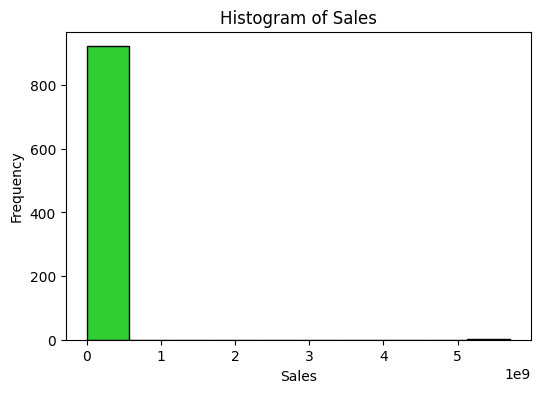

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.hist(df["Sales"], bins=10, color="limegreen", edgecolor="black")
plt.title("Histogram of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

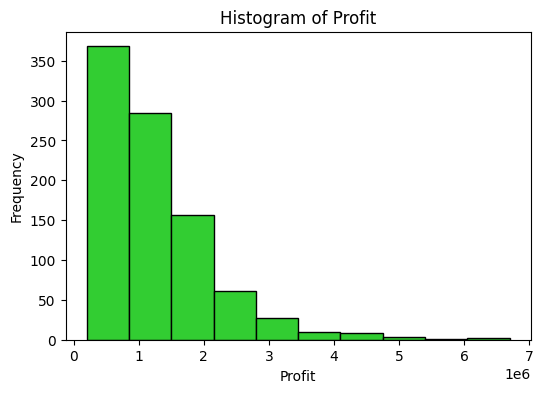

In [18]:
plt.figure(figsize=(6, 4))
plt.hist(df["Profit"], bins=10, color="limegreen", edgecolor="black")
plt.title("Histogram of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

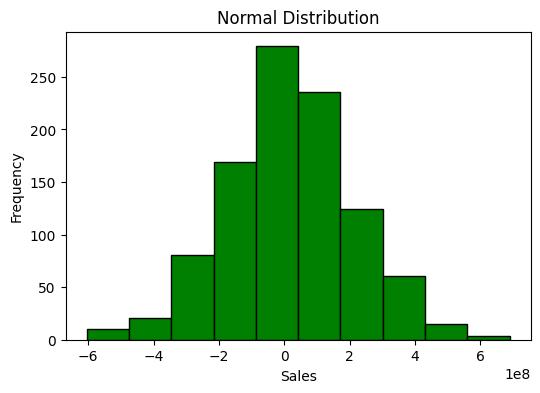

In [19]:
import numpy as np
normal = np.random.normal(df["Sales"].mean(), df["Sales"].std(), 1000)
plt.figure(figsize=(6, 4))
plt.hist(normal, bins=10, color="green", edgecolor="black")
plt.title("Normal Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

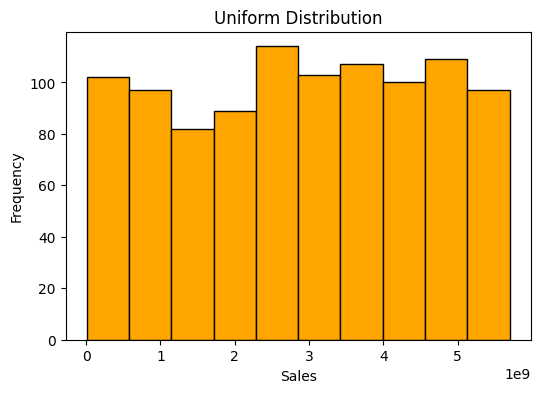

In [20]:
uniform = np.random.uniform(df["Sales"].min(), df["Sales"].max(), 1000)
plt.figure(figsize=(6, 4))
plt.hist(uniform, bins=10, color="orange", edgecolor="black")
plt.title("Uniform Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

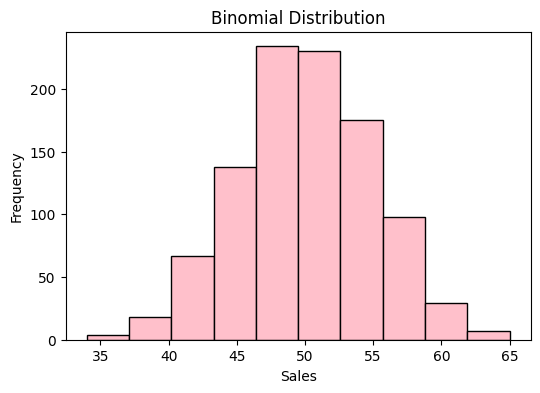

In [21]:
binomial = np.random.binomial(100, 0.5, 1000)
plt.figure(figsize=(6, 4))
plt.hist(binomial, bins=10, color="pink", edgecolor="black")
plt.title("Binomial Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [22]:
# Helper function to compute sample statistics
def calc_stats(data):
    return pd.Series({
        "Sample Size": len(data),
        "Mean Sales": data["Sales"].mean(),
        "Std Dev Sales": data["Sales"].std(),
        "Mean Profit": data["Profit"].mean(),
        "Std Dev Profit": data["Profit"].std()
    })

In [23]:
sample_sizes = [10, 30, 50]

for n in sample_sizes:
    print(f"\n--- EVALUATION FOR SAMPLE SIZE n = {n} ---")

    # Simple Random Sampling
    sample1 = df.sample(n=n, random_state=42)

    # Systematic Sampling (k step)
    k = max(1, len(df) // n)
    sample2 = df.iloc[::k].head(n)

    # Stratified Sampling (based on Region)
    sample3 = df.groupby("Region", group_keys=False).apply(
        lambda x: x.sample(max(1, int(n * len(x) / len(df))), random_state=42)
    ).head(n)

    # Cluster Sampling (based on Product Category)
    top_cat = df["Product_Category"].value_counts().index[0]
    cluster_df = df[df["Product_Category"] == top_cat]
    sample4 = cluster_df.sample(n=min(n, len(cluster_df)), random_state=42)

    datasets = {
        "Population": df,
        "Simple Random": sample1,
        "Systematic": sample2,
        "Stratified": sample3,
        "Cluster": sample4
    }

    comparison = pd.DataFrame({name: calc_stats(data) for name, data in datasets.items()})
    print(comparison)


--- EVALUATION FOR SAMPLE SIZE n = 10 ---
                  Population  Simple Random    Systematic    Stratified  \
Sample Size     9.230000e+02   1.000000e+01  1.000000e+01  1.000000e+01   
Mean Sales      2.541975e+07   1.567359e+07  3.822300e+06  1.634500e+07   
Std Dev Sales   1.896344e+08   1.708052e+07  9.924205e+06  1.574665e+07   
Mean Profit     1.233261e+06   1.010000e+06  9.900000e+05  9.200000e+05   
Std Dev Profit  8.662438e+05   6.063552e+05  7.187180e+05  6.250333e+05   

                     Cluster  
Sample Size     1.000000e+01  
Mean Sales      2.985459e+07  
Std Dev Sales   7.341682e+07  
Mean Profit     1.220000e+06  
Std Dev Profit  1.150652e+06  

--- EVALUATION FOR SAMPLE SIZE n = 30 ---
                  Population  Simple Random    Systematic    Stratified  \
Sample Size     9.230000e+02   3.000000e+01  3.000000e+01  3.000000e+01   
Mean Sales      2.541975e+07   1.694532e+07  1.599240e+07  1.608197e+07   
Std Dev Sales   1.896344e+08   1.613604e+07  2.79854

In [24]:
# TASK 3: CLT & CONFIDENCE INTERVALS WITH TESTS (From Practical 5 Style)
print("CLT, CONFIDENCE INTERVALS & HYPOTHESIS TESTING")
print("="*50)

# Sample selection (n=100)
sample_df = df.sample(n=100, random_state=42)
data = sample_df['Sales'].values
n = len(data)

sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)

print("Sample Size:", n)
print("Sample mean:", sample_mean)
print("Sample Standard Deviation:", sample_std)

CLT, CONFIDENCE INTERVALS & HYPOTHESIS TESTING
Sample Size: 100
Sample mean: 14898087.62
Sample Standard Deviation: 15502247.698174998


In [25]:
# T Confidence Interval (95%)
import scipy.stats as stats
confidence = 0.95
standard_error = sample_std / np.sqrt(n)
critical_value = stats.t.ppf((1 + confidence) / 2, n - 1)
margin_error = critical_value * standard_error
lower = sample_mean - margin_error
upper = sample_mean + margin_error
print("95% T Confidence Interval:")
print("(", lower, ",", upper, ")")

95% T Confidence Interval:
( 11822105.35307947 , 17974069.886920527 )


In [26]:
population_std = df['Sales'].std()
z_critical = 1.96
standard_error_z = population_std / np.sqrt(n)
margin_error_z = z_critical * standard_error_z
lower_z = sample_mean - margin_error_z
upper_z = sample_mean + margin_error_z
print("\n95% Z Confidence Interval:")
print("(", lower_z, ",", upper_z, ")")


95% Z Confidence Interval:
( -22270247.819803715 , 52066423.05980371 )


In [27]:
# 1. One Sample Z-test
mu = df['Sales'].mean()
z_score = (sample_mean - mu) / (population_std / np.sqrt(n))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_score)))
print("\n--- One Sample Z-Test ---")
print("Z-score:", z_score)
print("P-value:", p_value_z)


--- One Sample Z-Test ---
Z-score: -0.5548393879165681
P-value: 0.5790045232927603


In [28]:
alpha = 0.05
if p_value_z < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Fail to reject the null hypothesis


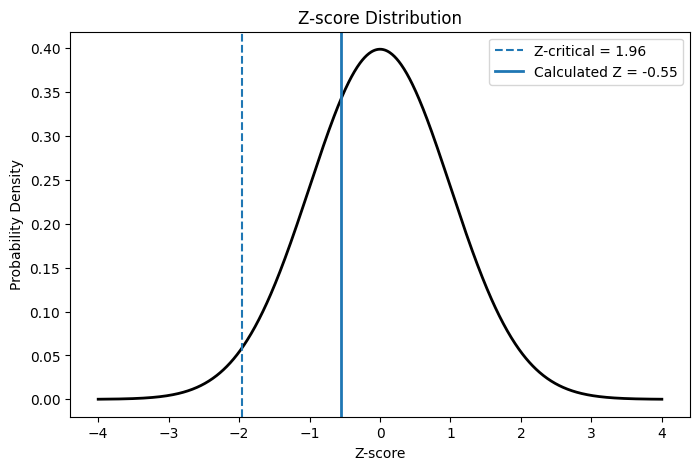

In [29]:
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y, color='black', linewidth=2)
plt.axvline(-z_critical, linestyle="--", label=f"Z-critical = {z_critical:.2f}")
plt.axvline(z_score, linestyle="-", linewidth=2, label=f"Calculated Z = {z_score:.2f}")
plt.xlabel("Z-score")
plt.ylabel("Probability Density")
plt.title("Z-score Distribution")
plt.legend()
plt.show()

In [30]:
# 2. One Sample T-test
t_statistic, p_value_t = stats.ttest_1samp(data, popmean=mu)
print("\n--- One Sample T-Test ---")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value_t, 4))
print("Hypothesized Mean:", mu)


--- One Sample T-Test ---
T-statistic: -6.7872
P-value: 0.0
Hypothesized Mean: 25419749.09209101


In [31]:
if p_value_t < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


In [32]:
# 3. Two Sample T-Test
group_ca = df[df['Region'] == 'CA']['Sales']
group_ny = df[df['Region'] == 'NY']['Sales']
t_stat_2, p_val_2 = stats.ttest_ind(group_ca, group_ny)
print(f"\n--- Two-Sample T-Test (CA vs NY) ---")
print(f"T-statistic: {t_stat_2:.4f}, P-value: {p_val_2:.4f}")


--- Two-Sample T-Test (CA vs NY) ---
T-statistic: 2.9152, P-value: 0.0037


In [33]:
# 4. Paired T-Test
t_stat_p, p_val = stats.ttest_rel(df['age_first_funding_year'], df['age_last_funding_year'])
print(f"\n--- Paired T-Test (First vs Last Funding Age) ---")
print(f"T-statistic: {t_stat_p:.4f}, P-value: {p_val:.4e}")


--- Paired T-Test (First vs Last Funding Age) ---
T-statistic: -26.6047, P-value: 3.5158e-116


In [34]:
# 6. Chi-Square Test
contingency = pd.crosstab(df['is_CA'], df['has_VC'])
chi2_stat, p_val, dof, _ = stats.chi2_contingency(contingency)
print(f"\n--- Chi-Square Test of Independence ---")
print(f"Chi2-statistic: {chi2_stat:.4f}, P-value: {p_val:.4f}")


--- Chi-Square Test of Independence ---
Chi2-statistic: 4.0538, P-value: 0.0441


In [35]:
# ------------------------------------------------------------------------------
# TASK 4: CORRELATION & COVARIANCE ANALYSIS
# ------------------------------------------------------------------------------
print("\n" + "="*50)
print("CORRELATION AND COVARIANCE ANALYSIS")
print("="*50)

cov_val = df['Sales'].cov(df['Profit'])
pearson_r, p_pearson = stats.pearsonr(df['Sales'], df['Profit'])
spearman_rho, p_spearman = stats.spearmanr(df['Sales'], df['Profit'])

print(f"Covariance (Sales, Profit): {cov_val:.2f}")
print(f"Pearson Correlation (r):   {pearson_r:.4f} (P-value: {p_pearson:.4e})")
print(f"Spearman Correlation (rho): {spearman_rho:.4f} (P-value: {p_spearman:.4e})")


CORRELATION AND COVARIANCE ANALYSIS
Covariance (Sales, Profit): 19031634320144.05
Pearson Correlation (r):   0.1159 (P-value: 4.2041e-04)
Spearman Correlation (rho): 0.4408 (P-value: 3.6899e-45)


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [37]:
# ------------------------------------------------------------------------------
# LAB 8: MULTIPLE REGRESSION & MACHINE LEARNING MODELS
# ------------------------------------------------------------------------------
features = ['funding_rounds', 'relationships', 'age_last_funding_year', 'milestones', 'avg_participants']
X = df[features].fillna(0)
y = df['Sales']

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
scaler = StandardScaler()
X_train_Scaler = scaler.fit_transform(X_train)
X_test_Scaler = scaler.transform(X_test)

In [40]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)

print("\n" + "="*50)
print("Multiple Linear Regression:")
print("="*50)
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)


Multiple Linear Regression:
Intercept: -34052105.36689118
Coefficients: [ 9924783.84283644  2592665.25105187  5278592.78395254 -6633886.89045882
  3114196.12957863]


In [41]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_Scaler, y_train)
ridge_pred = ridge_model.predict(X_test_Scaler)
print("Alpha:", ridge_model.alpha)
print("Intercept:", round(ridge_model.intercept_, 2))
print("Coefficients:", ridge_model.coef_)

Alpha: 1.0
Intercept: 26904076.56
Coefficients: [13865165.58764419 18565282.59003951 16182868.70543042 -8917834.94562806
  5912364.69446274]


In [42]:
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_Scaler, y_train)
lasso_pred = lasso_model.predict(X_test_Scaler)
print("Alpha:", lasso_model.alpha)
print("Intercept:", round(lasso_model.intercept_, 2))

Alpha: 0.1
Intercept: 26904076.56


In [43]:
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
print("Maximum depth:", tree_model.max_depth)

Maximum depth: 3


In [44]:
forest_model = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42)
forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)
print("Number of trees:", forest_model.n_estimators)
print("Maximum depth:", forest_model.max_depth)
print("Number of features:", forest_model.n_features_in_)

Number of trees: 100
Maximum depth: 3
Number of features: 5


In [45]:
prediction = {
    'Multiple Regression': multiple_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree': tree_pred,
    'Random Forest': forest_pred
}

In [46]:
results = []
for model_name, pred_values in prediction.items():
    mae = mean_absolute_error(y_test, pred_values)
    mse = mean_squared_error(y_test, pred_values)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred_values)

    results.append([model_name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']
)

print("\n" + "="*70)
print("MODEL EVALUATION COMPARISON TABLE")
print("="*70)
print(results_df.sort_values(by='R2', ascending=False).to_string(index=False))


MODEL EVALUATION COMPARISON TABLE
              Model          MAE          MSE         RMSE        R2
      Random Forest 1.537369e+07 1.709719e+15 4.134875e+07  0.033808
      Decision Tree 1.583945e+07 1.719951e+15 4.147229e+07  0.028026
   Ridge Regression 2.303742e+07 2.193055e+15 4.683006e+07 -0.239333
   Lasso Regression 2.305499e+07 2.194739e+15 4.684804e+07 -0.240285
Multiple Regression 2.305499e+07 2.194739e+15 4.684804e+07 -0.240285


In [47]:
# Print Predictor Effects (Multiple Linear Regression Coefficients)
lr = multiple_model
print("\nPredictor Effects (Linear Regression Coefficients):")
for feat, coef in zip(features, lr.coef_):
    print(f"- {feat}: {coef:.4f}")
print(f"- Intercept: {lr.intercept_:.4f}")


Predictor Effects (Linear Regression Coefficients):
- funding_rounds: 9924783.8428
- relationships: 2592665.2511
- age_last_funding_year: 5278592.7840
- milestones: -6633886.8905
- avg_participants: 3114196.1296
- Intercept: -34052105.3669


In [48]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [49]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical variables:", numerical_cols)
print("Categorical variables:", categorical_cols)

Numerical variables: ['Unnamed: 0', 'latitude', 'longitude', 'labels', 'age_first_funding_year', 'age_last_funding_year', 'age_first_milestone_year', 'age_last_milestone_year', 'relationships', 'funding_rounds', 'funding_total_usd', 'milestones', 'is_CA', 'is_NY', 'is_MA', 'is_TX', 'is_otherstate', 'is_software', 'is_web', 'is_mobile', 'is_enterprise', 'is_advertising', 'is_gamesvideo', 'is_ecommerce', 'is_biotech', 'is_consulting', 'is_othercategory', 'has_VC', 'has_angel', 'has_roundA', 'has_roundB', 'has_roundC', 'has_roundD', 'avg_participants', 'is_top500', 'Sales', 'Profit']
Categorical variables: ['state_code', 'zip_code', 'id', 'city', 'Unnamed: 6', 'name', 'founded_at', 'closed_at', 'first_funding_at', 'last_funding_at', 'state_code.1', 'category_code', 'object_id', 'status', 'Region', 'Product_Category']


/tmp/ipykernel_1714/578871959.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


In [50]:
from sklearn.preprocessing import LabelEncoder

# Encode the categorical 'status' column to numeric 'status_encoded'
le = LabelEncoder()
df['status_encoded'] = le.fit_transform(df['status'])

# Select numerical features and calculate correlation
num_df = df.select_dtypes(include=['int64', 'float64'])
correlation_with_target = num_df.corr()['status_encoded'].sort_values(ascending=False)
print("\nCorrelation of features with Startup Status:")
print(correlation_with_target)


Correlation of features with Startup Status:
status_encoded              1.000000
is_otherstate               0.169067
age_first_funding_year      0.075637
has_angel                   0.072840
is_ecommerce                0.072193
Unnamed: 0                  0.068721
has_VC                      0.056515
is_TX                       0.045309
is_othercategory            0.042408
longitude                   0.036092
is_gamesvideo               0.025893
is_web                      0.000873
is_biotech                 -0.000104
is_consulting              -0.002373
is_mobile                  -0.007312
is_software                -0.012429
Sales                      -0.040176
funding_total_usd          -0.040176
is_advertising             -0.044355
latitude                   -0.046560
is_NY                      -0.059996
age_last_funding_year      -0.073731
is_enterprise              -0.073772
is_CA                      -0.077217
is_MA                      -0.081735
has_roundD                 -0

In [51]:
covariance_matrix = num_df.cov()
print("\nCovariance between key features and Startup Status:")
print(covariance_matrix['status_encoded'].head(6))


Covariance between key features and Startup Status:
Unnamed: 0                10.962984
latitude                  -0.083309
longitude                  0.386518
labels                    -0.228696
age_first_funding_year     0.090807
age_last_funding_year     -0.104648
Name: status_encoded, dtype: float64


In [52]:
features = ['funding_rounds', 'relationships', 'age_last_funding_year', 'milestones', 'avg_participants', 'funding_total_usd']

X = df[features].fillna(df[features].mean())
y = df['status_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining Set Size: {X_train.shape[0]}")
print(f"Testing Set Size: {X_test.shape[0]}")


Training Set Size: 738
Testing Set Size: 185


In [53]:
# ------------------------------------------------------------------------------
# STEP 5: MODEL TRAINING & ACCURACY COMPARISON
# ------------------------------------------------------------------------------

# 1. Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, lr_pred)
print(f"\nLogistic Regression Accuracy: {lr_acc:.4f}")


Logistic Regression Accuracy: 0.7838


In [54]:
# 2. Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_acc = accuracy_score(y_test, dt_pred)
print(f"Decision Tree Accuracy:       {dt_acc:.4f}")

Decision Tree Accuracy:       0.7405


In [55]:
# 3. Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest Accuracy:       {rf_acc:.4f}")

Random Forest Accuracy:       0.7838


In [56]:
# 4. K-Nearest Neighbors (KNN)
knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)
knn_acc = accuracy_score(y_test, knn_pred)
print(f"KNN Accuracy:                 {knn_acc:.4f}")

KNN Accuracy:                 0.7459


In [57]:
# 5. Support Vector Machine (SVM)
svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_pred = svm_model.predict(X_test_scaled)
svm_acc = accuracy_score(y_test, svm_pred)
print(f"SVM Accuracy:                 {svm_acc:.4f}")

SVM Accuracy:                 0.8054


In [58]:
# ------------------------------------------------------------------------------
# STEP 6: MODEL SELECTION & SAVING WITH JOBLIB
# ------------------------------------------------------------------------------
models = {
    'Logistic Regression': (lr_model, lr_acc, True),
    'Decision Tree': (dt_model, dt_acc, False),
    'Random Forest': (rf_model, rf_acc, False),
    'KNN': (knn_model, knn_acc, True),
    'SVM': (svm_model, svm_acc, True)
}

In [59]:
best_model_name = max(models, key=lambda k: models[k][1])
best_model, best_accuracy, needs_scale = models[best_model_name]

print(f"\n--- Best Performing Model: {best_model_name} with Accuracy {best_accuracy:.4f} ---")


--- Best Performing Model: SVM with Accuracy 0.8054 ---


In [62]:
import joblib
joblib.dump(best_model, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Model and scaler saved successfully!")

Model and scaler saved successfully!
